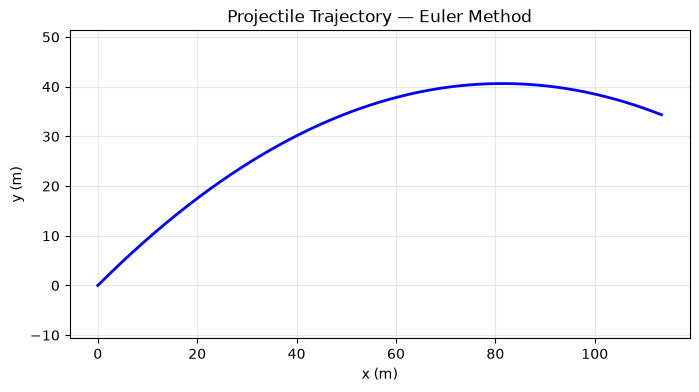

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
g = 9.81         # m/s², gravitational acceleration
dt = 0.01        # time step in seconds
t_max = 4.0      # total simulation time

# Initial conditions: launched at 45°, speed 20 m/s
v0 = 40.0
angle = np.radians(45)
x, y = 0.0, 0.0
vx, vy = v0 * np.cos(angle), v0 * np.sin(angle)

# Storage lists for plotting
xs, ys, ts = [x], [y], [0.0]

# Euler integration loop
t = 0.0
while t < t_max and y >= 0.0:
    # Compute acceleration (only gravity here)
    ax = 0.0
    ay = -g

    # Update velocity (Euler)
    vx = vx + ax * dt
    vy = vy + ay * dt

    # Update position (Euler)
    x = x + vx * dt
    y = y + vy * dt

    t += dt
    xs.append(x)
    ys.append(y)
    ts.append(t)

# Plot trajectory
plt.figure(figsize=(8, 4))
plt.plot(xs, ys, 'b-', linewidth=2)
plt.xlabel('x (m)')
plt.ylabel('y (m)')
plt.title('Projectile Trajectory — Euler Method')
plt.grid(True, alpha=0.3)
plt.axis('equal')
plt.show()

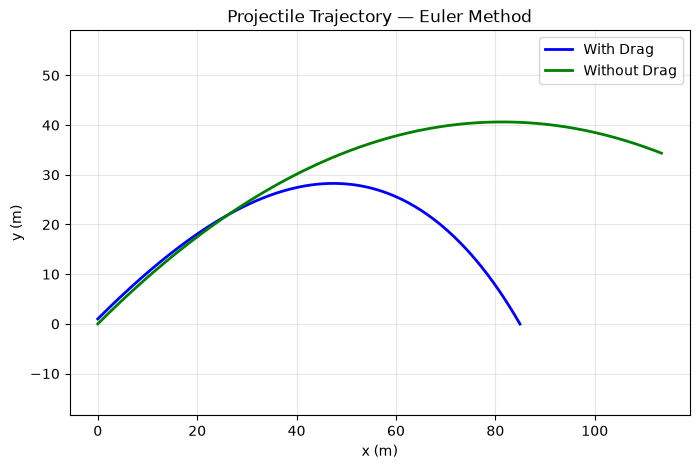

In [20]:
# Physical parameters
g = 9.81
m = 0.145         # mass of a baseball, kg
r = 0.0366        # radius of a baseball, m
Cd = 0.47         # drag coefficient for a sphere
rho = 1.225       # air density, kg/m³
A = np.pi * r**2  # cross-sectional area

# Combine the drag constants into one number
b = 0.5 * Cd * rho * A  # so F_drag = -b * |v| * v

dt = 0.01
v0 = 40.0  # ~90 mph fastball
angle = np.radians(45)

# Initial state
x, y = 0.0, 1.0   # released from 1 m height
vx, vy = v0 * np.cos(angle), v0 * np.sin(angle)

xs_drag, ys_drag = [x], [y]

t = 0.0
while y >= 0.0:
    # Speed (magnitude of velocity)
    speed = np.sqrt(vx**2 + vy**2)

    # Forces: gravity + drag
    Fx = -(b / m) * speed * vx
    Fy = -g - (b / m) * speed * vy

    # Euler update
    vx += Fx * dt
    vy += Fy * dt
    x += vx * dt
    y += vy * dt

    t += dt
    xs_drag.append(x)
    ys_drag.append(y)

plt.figure(figsize=(8,5)) 
plt.plot(xs_drag, ys_drag, 'b-', linewidth=2, label='With Drag')
plt.plot(xs, ys, 'g-', linewidth=2, label='Without Drag')  # without drag for comparison
plt.xlabel('x (m)')
plt.ylabel('y (m)')
plt.title('Projectile Trajectory — Euler Method')
plt.grid(True, alpha=0.3)
plt.axis('equal')
plt.legend()
plt.show()




In [21]:
# Convergence test: Euler for free fall
# Exact answer: y(t) = y0 + vy0*t - 0.5*g*t²

g = 9.81
t_final = 2.0
y0, vy0 = 0.0, 20.0
y_exact = y0 + vy0 * t_final - 0.5 * g * t_final**2

for dt in [0.5, 0.1, 0.01, 0.001]:
    y, vy_curr = y0, vy0
    t = 0.0
    n_steps = int(t_final / dt)
    for _ in range(n_steps):
        vy_curr += -g * dt
        y += vy_curr * dt   # Wait — is this Euler or something else?
        t += dt
    error = abs(y - y_exact)
    print(f"dt = {dt:.4f}  |  y_final = {y:.6f}  |  error = {error:.6f}")

dt = 0.5000  |  y_final = 15.475000  |  error = 4.905000
dt = 0.1000  |  y_final = 19.399000  |  error = 0.981000
dt = 0.0100  |  y_final = 20.281900  |  error = 0.098100
dt = 0.0010  |  y_final = 20.370190  |  error = 0.009810


In [ ]:
''' 
import numpy as np

# Creating arrays
a = np.array([1.0, 2.0, 3.0])       # from a list
t = np.arange(0, 10, 0.01)          # evenly spaced values
z = np.zeros(100)                     # array of zeros

# Element-wise math (no loops needed!)
y = 0.5 * 9.81 * t**2                # applies to every element
speed = np.sqrt(vx**2 + vy**2)       # works on arrays

# Useful functions
np.sin(theta)                         # trig (radians!)
np.radians(45)                        # degrees → radians
np.linalg.norm(v)                     # magnitude of a vector
np.max(y), np.argmax(y)               # max value and its index

# Stacking results (useful for storing trajectories)
positions = np.column_stack([xs, ys])  # Nx2 array 
'''
# This is just to see what I need to know. The code will error if left ouside of block quotes

In [ ]:
'''
import matplotlib.pyplot as plt

# Basic line plot
plt.figure(figsize=(8, 5))
plt.plot(x_data, y_data, 'b-', label='Simulation', linewidth=2)
plt.plot(x_exact, y_exact, 'r--', label='Exact', linewidth=1.5)
plt.xlabel('x (m)', fontsize=12)
plt.ylabel('y (m)', fontsize=12)
plt.title('Projectile Motion with Drag', fontsize=14)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Subplots (multiple panels)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.plot(t, x, 'b-')
ax1.set_xlabel('t (s)')
ax1.set_ylabel('x (m)')
ax1.set_title('Horizontal Position')
ax2.plot(t, y, 'r-')
ax2.set_xlabel('t (s)')
ax2.set_ylabel('y (m)')
ax2.set_title('Vertical Position')
plt.tight_layout()
plt.show()
'''
# this is just to see what I need to know. The code will error if left ouside of block quotes

"\nimport matplotlib.pyplot as plt\n\n# Basic line plot\nplt.figure(figsize=(8, 5))\nplt.plot(x_data, y_data, 'b-', label='Simulation', linewidth=2)\nplt.plot(x_exact, y_exact, 'r--', label='Exact', linewidth=1.5)\nplt.xlabel('x (m)', fontsize=12)\nplt.ylabel('y (m)', fontsize=12)\nplt.title('Projectile Motion with Drag', fontsize=14)\nplt.legend(fontsize=11)\nplt.grid(True, alpha=0.3)\nplt.tight_layout()\nplt.show()\n\n# Subplots (multiple panels)\nfig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))\nax1.plot(t, x, 'b-')\nax1.set_xlabel('t (s)')\nax1.set_ylabel('x (m)')\nax1.set_title('Horizontal Position')\nax2.plot(t, y, 'r-')\nax2.set_xlabel('t (s)')\nax2.set_ylabel('y (m)')\nax2.set_title('Vertical Position')\nplt.tight_layout()\nplt.show()\n"

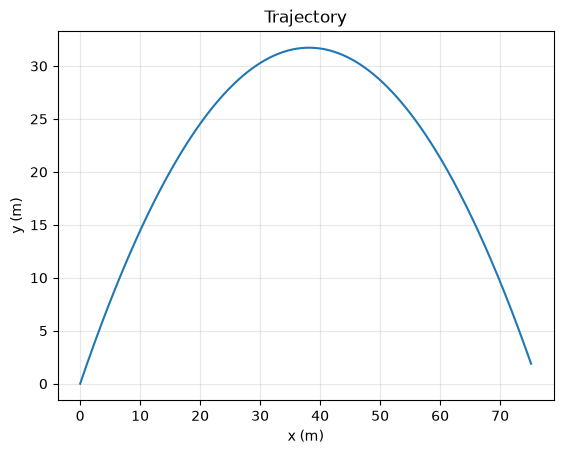

In [26]:
import numpy as np
import matplotlib.pyplot as plt

# ─── Parameters ───────────────────────────────────────────────
g = 9.81
m = 0.145
dt = 0.01
t_max = 5.0

# ─── Force function ───────────────────────────────────────────
def compute_acceleration(x, y, vx, vy):
    """Return (ax, ay) given current state."""
    ax = 0.0
    ay = -g
    return ax, ay

# ─── Initial conditions ───────────────────────────────────────
x, y = 0.0, 0.0
vx, vy = 15.0, 25.0

# ─── Storage ──────────────────────────────────────────────────
trajectory = {'t': [0], 'x': [x], 'y': [y], 'vx': [vx], 'vy': [vy]}

# ─── Simulation loop ──────────────────────────────────────────
t = 0.0
while t < t_max and y >= 0:
    ax, ay = compute_acceleration(x, y, vx, vy)
    vx += ax * dt
    vy += ay * dt
    x += vx * dt
    y += vy * dt
    t += dt
    for key, val in zip(['t','x','y','vx','vy'], [t,x,y,vx,vy]):
        trajectory[key].append(val)

# ─── Visualization ────────────────────────────────────────────
plt.plot(trajectory['x'], trajectory['y'])
plt.xlabel('x (m)'); plt.ylabel('y (m)')
plt.title('Trajectory'); plt.grid(True, alpha=0.3)
plt.show()

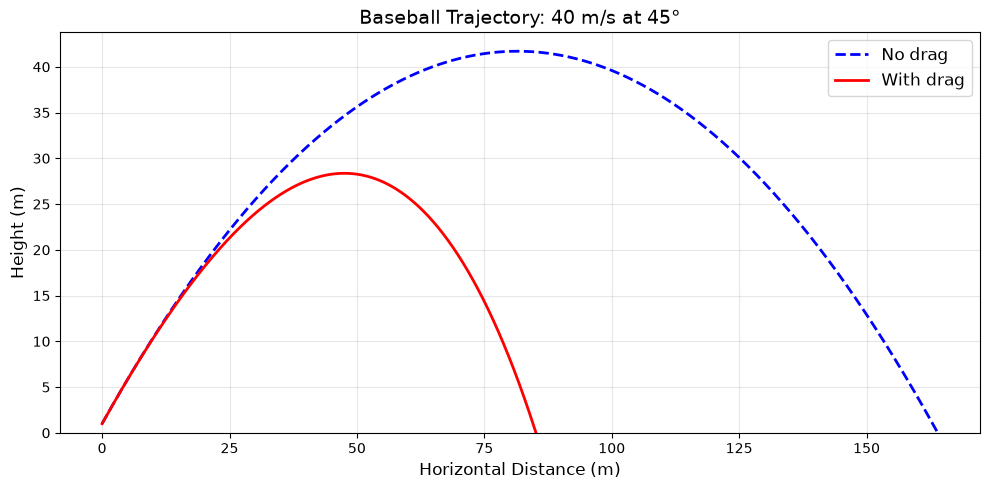

Range without drag: 163.8 m
Range with drag:    85.1 m
Drag reduces range by 48%


In [27]:
#  Worked Example: Baseball with Drag
import numpy as np
import matplotlib.pyplot as plt

# ─── Parameters ───────────────────────────────────────────────
g = 9.81            # gravitational acceleration (m/s²)
m = 0.145            # baseball mass (kg)
r = 0.0366           # baseball radius (m)
Cd = 0.47            # drag coefficient (sphere)
rho = 1.225          # air density (kg/m³)
A = np.pi * r**2     # cross-sectional area (m²)
b = 0.5 * Cd * rho * A

v0 = 40.0            # launch speed (m/s)
angle = np.radians(45)
dt = 0.005

# ─── Force functions ──────────────────────────────────────────
def accel_no_drag(x, y, vx, vy):
    return 0.0, -g

def accel_with_drag(x, y, vx, vy):
    speed = np.sqrt(vx**2 + vy**2)
    ax = -(b / m) * speed * vx
    ay = -g - (b / m) * speed * vy
    return ax, ay

# ─── Simulation function ──────────────────────────────────────
def simulate(accel_func, x0, y0, vx0, vy0, dt, t_max=10.0):
    x, y, vx, vy = x0, y0, vx0, vy0
    xs, ys = [x], [y]
    t = 0.0
    while t < t_max and y >= 0.0:
        ax, ay = accel_func(x, y, vx, vy)
        vx += ax * dt
        vy += ay * dt
        x  += vx * dt
        y  += vy * dt
        t  += dt
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)

# ─── Run both simulations ─────────────────────────────────────
vx0 = v0 * np.cos(angle)
vy0 = v0 * np.sin(angle)

x_nd, y_nd = simulate(accel_no_drag,    0, 1, vx0, vy0, dt)
x_wd, y_wd = simulate(accel_with_drag,  0, 1, vx0, vy0, dt)

# ─── Plot ─────────────────────────────────────────────────────
plt.figure(figsize=(10, 5))
plt.plot(x_nd, y_nd, 'b--', label='No drag', linewidth=2)
plt.plot(x_wd, y_wd, 'r-',  label='With drag', linewidth=2)
plt.xlabel('Horizontal Distance (m)', fontsize=12)
plt.ylabel('Height (m)', fontsize=12)
plt.title('Baseball Trajectory: 40 m/s at 45°', fontsize=14)
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.ylim(bottom=0)
plt.tight_layout()
plt.show()

# ─── Report ───────────────────────────────────────────────────
range_nd = x_nd[np.argmin(np.abs(y_nd[1:]))]  # approximate landing x
range_wd = x_wd[np.argmin(np.abs(y_wd[1:]))]
print(f"Range without drag: {range_nd:.1f} m")
print(f"Range with drag:    {range_wd:.1f} m")
print(f"Drag reduces range by {100*(1 - range_wd/range_nd):.0f}%")